# Linear static analysis of a plate

A simply supported plate of `Quad4` elements under a central point load. The
largest normal displacement $w$ is compared with the Navier solution of the
Kirchhoff plate of Timoshenko and Woinowsky-Krieger (1959), on four meshes,
and the internal forces with the external forces and the support reactions.
The steps follow [Overview and workflow](../overview.rst); the theory of the
analysis is in [Linear static analyses](../linear_analyses.rst) and
[Boundary conditions and prescribed displacements](../boundary_conditions.rst),
that of the element in [Quad4: assumed transverse shear strains (MITC4)](../shell_quad4.rst).
The full references are at the end of the notebook.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.sparse import coo_matrix

from pyfe3d import DOF, DOUBLE, INT, Quad4, Quad4Data, Quad4Probe
from pyfe3d.shellprop_utils import isotropic_plate
from pyfe3d.solver import solve

## The problem and the reference value

The plate has the sides $a = 3$ m along $x$ and $b = 7$ m along $y$, the
thickness $h = 0.005$ m, $E = 200$ GPa and $\nu = 0.3$. The edges have $w = 0$
with the rotations free, and the in-plane translations of every node are
held, which leaves the bending problem of the flat plate. A unit load $P$ acts
at the centre.

For the Kirchhoff plate of bending stiffness $D = E h^3/(12 (1 - \nu^2))$, the
Navier double series of the deflection under a point load, Eq. (133) of
Timoshenko and Woinowsky-Krieger (1959, Art. 29, p. 111), evaluated at the
centre and summed over one index in their Art. 34, p. 143, Eq. (147), is

$$
w_{max} = \alpha \frac{P a^2}{D}, \qquad
\alpha = \frac{1}{2 \pi^3} \sum_{m = 1, 3, 5, \dots} \frac{1}{m^3}
\left(\tanh \alpha_m - \frac{\alpha_m}{\cosh^2 \alpha_m}\right), \qquad
\alpha_m = \frac{m \pi b}{2 a}
$$

The series converges fast; it is truncated at $m = 79$:

In [2]:
a = 3.
b = 7.
h = 0.005 # m
E = 200.e9
nu = 0.3
P = 1.

D = E*h**3/(12*(1 - nu**2))
m = np.arange(1, 80, 2)
alpha_m = m*np.pi*b/(2*a)
alpha = np.sum((np.tanh(alpha_m) - alpha_m/np.cosh(alpha_m)**2)/m**3)/(2*np.pi**3)
wmax_ref = alpha*P*a**2/D
print('alpha = %.6f' % alpha)
print('w_max = %.6e m' % wmax_ref)

alpha = 0.016785
w_max = 6.598363e-05 m


For $b/a = 7/3$ the coefficient lies between the values 0.01651 and 0.01690
of their Table 23 for $b/a = 2$ and 3.

`Quad4` is a shear-deformable (Mindlin) element, whereas the reference is the
Kirchhoff plate. Under a point load the transverse shear deflection of the
Mindlin plate is logarithmically singular: the shear part of its Navier
series, $\frac{4 P}{\pi^2 a b A_{55}} \sum_{m, n} \left[(m/a)^2 +
(n/b)^2\right]^{-1}$, diverges. With $a/h = 600$ it is nevertheless small:
truncated at the wavenumbers that the meshes below resolve, it adds $2.0
\times 10^{-5}$ to $3.6 \times 10^{-5}$ of the reference deflection.

## The model

The function below builds a mesh of `nx` by `ny` nodes. Each element receives
the node ids `n1, ..., n4`, counterclockwise about the normal $+z$, the
positions `c1, ..., c4` of their dofs in the global vectors and `init_k_KC0`,
its position in the sparse arrays of $\boldsymbol{K}_{C0}$; `K6ROT` is the
stiffness of the drilling rotation. The boundary conditions are the Boolean
arrays `bk` (known dofs) and `bu = ~bk`, and the free dofs are solved with
`pyfe3d.solver.solve`:

In [3]:
def solve_plate(nx, ny):
    data = Quad4Data()
    probe = Quad4Probe()
    xtmp = np.linspace(0, a, nx)
    ytmp = np.linspace(0, b, ny)
    xmesh, ymesh = np.meshgrid(xtmp, ytmp)
    ncoords = np.vstack((xmesh.T.flatten(), ymesh.T.flatten(),
                         np.zeros(nx*ny))).T
    x = ncoords[:, 0]
    y = ncoords[:, 1]
    ncoords_flatten = ncoords.flatten()

    nids = 1 + np.arange(ncoords.shape[0])
    nid_pos = dict(zip(nids, np.arange(len(nids))))
    nids_mesh = nids.reshape(nx, ny)
    n1s = nids_mesh[:-1, :-1].flatten()
    n2s = nids_mesh[1:, :-1].flatten()
    n3s = nids_mesh[1:, 1:].flatten()
    n4s = nids_mesh[:-1, 1:].flatten()
    num_elements = len(n1s)
    N = DOF*nx*ny

    KC0r = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=INT)
    KC0c = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=INT)
    KC0v = np.zeros(data.KC0_SPARSE_SIZE*num_elements, dtype=DOUBLE)
    prop = isotropic_plate(thickness=h, E=E, nu=nu)
    quads = []
    for k, (n1, n2, n3, n4) in enumerate(zip(n1s, n2s, n3s, n4s)):
        quad = Quad4(probe)
        quad.n1, quad.n2, quad.n3, quad.n4 = n1, n2, n3, n4
        quad.c1 = DOF*nid_pos[n1]
        quad.c2 = DOF*nid_pos[n2]
        quad.c3 = DOF*nid_pos[n3]
        quad.c4 = DOF*nid_pos[n4]
        quad.init_k_KC0 = k*data.KC0_SPARSE_SIZE
        quad.K6ROT = 100.
        quad.update_rotation_matrix(ncoords_flatten)
        quad.update_probe_xe(ncoords_flatten)
        quad.update_KC0(KC0r, KC0c, KC0v, prop)
        quads.append(quad)
    KC0 = coo_matrix((KC0v, (KC0r, KC0c)), shape=(N, N)).tocsc()

    # w = 0 at the edges, u = v = 0 everywhere
    bk = np.zeros(N, dtype=bool)
    edges = np.isclose(x, 0.) | np.isclose(x, a) | np.isclose(y, 0) | np.isclose(y, b)
    bk[2::DOF] = edges
    bk[0::DOF] = True
    bk[1::DOF] = True
    bu = ~bk

    # point load at the centre node
    fext = np.zeros(N)
    fext[2::DOF][np.isclose(x, a/2) & np.isclose(y, b/2)] = P

    u = np.zeros(N)
    u[bu] = solve(KC0[bu, :][:, bu], fext[bu])
    return dict(xmesh=xmesh, ymesh=ymesh, x=ncoords_flatten, quads=quads,
                prop=prop, KC0=KC0, bk=bk, bu=bu, fext=fext, u=u,
                w=u[2::DOF].reshape(nx, ny).T, num_elements=num_elements)

## Convergence of the central deflection

The deflection converges from below to the reference, as the element is
stiffer than the continuum:

In [4]:
meshes = [(7, 11), (13, 21), (19, 31), (25, 41)]
print('%-9s %14s %14s %11s' % ('elements', 'w_max (m)', 'reference (m)',
                               'rel. diff.'))
errors = []
for nx, ny in meshes:
    res = solve_plate(nx, ny)
    wmax = res['w'].max()
    errors.append(wmax/wmax_ref - 1)
    print('%-9s %14.6e %14.6e %11.2e' % ('%dx%d' % (nx - 1, ny - 1), wmax,
                                         wmax_ref, errors[-1]))

elements       w_max (m)  reference (m)  rel. diff.
6x10        6.426015e-05   6.598363e-05   -2.61e-02
12x20       6.549552e-05   6.598363e-05   -7.40e-03
18x30       6.575388e-05   6.598363e-05   -3.48e-03


24x40       6.585078e-05   6.598363e-05   -2.01e-03


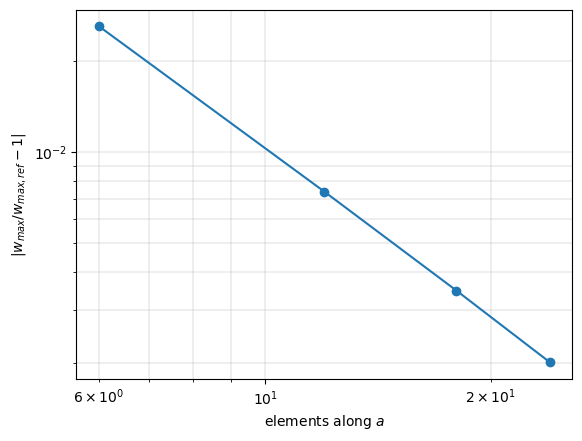

In [5]:
num_el_x = np.array([nx - 1 for nx, ny in meshes])
plt.loglog(num_el_x, np.abs(errors), 'o-')
plt.xlabel('elements along $a$')
plt.ylabel(r'$|w_{max}/w_{max,ref} - 1|$')
plt.grid(True, which='both', lw=0.3)
plt.show()

## Equilibrium: internal forces and reactions

On the 18 x 30 mesh, `update_fint` gives, element by element, the internal
force vector $\boldsymbol{F}_{int} = \boldsymbol{K}_{C0} \boldsymbol{u}$ from
the displacements given to the probe with `update_probe_ue`. It must equal the
external force vector completed at the constrained dofs by the reactions
$\boldsymbol{R}_k = \boldsymbol{K}_{C0_{ku}} \boldsymbol{u}_u$, the second
block row of the partitioned system of
[Boundary conditions and prescribed displacements](../boundary_conditions.rst),
with $\bar{\boldsymbol{u}}_k = \boldsymbol{0}$ and no load at the constrained
dofs. The vertical reactions add up to $-P$:

In [6]:
res = solve_plate(19, 31)
u, bk, bu = res['u'], res['bk'], res['bu']
fint = np.zeros_like(u)
for quad in res['quads']:
    quad.update_probe_xe(res['x'])
    quad.update_probe_ue(u)
    quad.update_fint(fint, res['prop'])
f = res['fext'].copy()
f[bk] = res['KC0'][bk, :][:, bu] @ u[bu]
print('max |F_int - (F_ext + R)| = %.2e N' % np.abs(fint - f).max())
print('sum of the vertical reactions = %.10f N' % f[2::DOF][bk[2::DOF]].sum())

max |F_int - (F_ext + R)| = 3.10e-11 N
sum of the vertical reactions = -1.0000000003 N


## Normal displacement

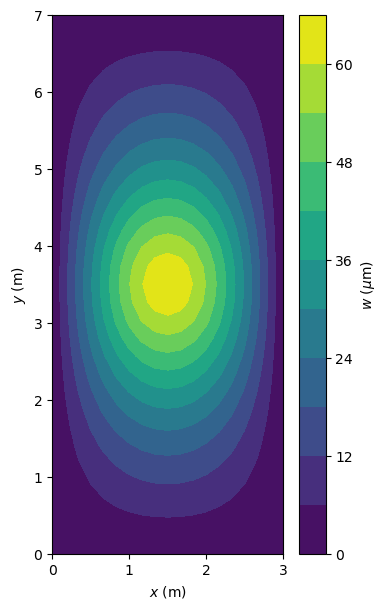

In [7]:
fig, ax = plt.subplots(figsize=(4, 7))
ax.set_aspect('equal')
cs = ax.contourf(res['xmesh'], res['ymesh'], res['w']*1e6, levels=10)
fig.colorbar(cs, label=r'$w$ ($\mu$m)')
ax.set_xlabel('$x$ (m)')
ax.set_ylabel('$y$ (m)')
plt.show()

## References

- Timoshenko, S. and Woinowsky-Krieger, S., Theory of Plates and Shells,
  2nd ed., McGraw-Hill, 1959.